# 05 — Kepler Feature Importance & Ablation



In [ ]:
import os, warnings, time
from pathlib import Path

os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)


DATA_DIR = Path("Kepler_Datasets")

def load_csv(filename):
    file_path = DATA_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Could not find {file_path.resolve()}"
        )

    return pd.read_csv(file_path)

X = load_csv('X_train.csv')
y = load_csv('y_train.csv')['target'].astype(int).to_numpy()
groups = load_csv('train_ids.csv')['kepid'].to_numpy()

folds = list(
    StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y, groups)
)

print(
    'Training observations:', len(X),
    '| Features:', X.shape[1],
    '| CV folds:', len(folds)
)

Training observations: 7662 | Features: 19 | CV folds: 5


In [6]:
def make_mlp():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu',
                              solver='adam', alpha=0.01, learning_rate_init=0.001,
                              batch_size=128, max_iter=90, n_iter_no_change=20,
                              tol=1e-4, early_stopping=False, random_state=42))
    ])

## 1. Permutation importance: effect on validation F1

In [7]:
permutation_rows = []
for fold_number, (train_idx, val_idx) in enumerate(folds, 1):
    model = make_mlp().fit(X.iloc[train_idx], y[train_idx])
    X_val, y_val = X.iloc[val_idx], y[val_idx]
    baseline_f1 = f1_score(y_val, model.predict(X_val))
    rng = np.random.RandomState(100 + fold_number)
    for feature in X.columns:
        for repeat in range(2):
            shuffled = X_val.copy()
            shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
            shuffled_f1 = f1_score(y_val, model.predict(shuffled))
            permutation_rows.append(dict(feature=feature, fold=fold_number,
                                         repeat=repeat + 1, baseline_f1=baseline_f1,
                                         permuted_f1=shuffled_f1,
                                         drop_f1=baseline_f1 - shuffled_f1))

permutation_folds = pd.DataFrame(permutation_rows)
importance = (permutation_folds.groupby('feature')
              .agg(mean_f1_drop=('drop_f1', 'mean'),
                   std_f1_drop=('drop_f1', 'std'))
              .reset_index().sort_values('mean_f1_drop', ascending=False))
print(importance.round(4).to_string(index=False))
permutation_folds.to_csv('kepler_permutation_importance_folds.csv', index=False)
importance.to_csv('kepler_feature_importance.csv', index=False)

         feature  mean_f1_drop  std_f1_drop
         koi_teq        0.1219       0.0183
    koi_duration        0.1192       0.0100
koi_num_transits        0.0869       0.0098
       koi_depth        0.0561       0.0095
koi_max_sngle_ev        0.0463       0.0046
       koi_steff        0.0456       0.0163
       koi_slogg        0.0431       0.0087
         koi_ror        0.0369       0.0100
       koi_smass        0.0316       0.0090
 koi_max_mult_ev        0.0273       0.0068
        koi_smet        0.0248       0.0097
      koi_impact        0.0197       0.0086
   koi_model_snr        0.0168       0.0049
      koi_period        0.0150       0.0070
         koi_sma        0.0122       0.0043
         koi_dor        0.0088       0.0102
       koi_insol        0.0043       0.0023
        koi_srad        0.0041       0.0049
        koi_prad        0.0012       0.0020


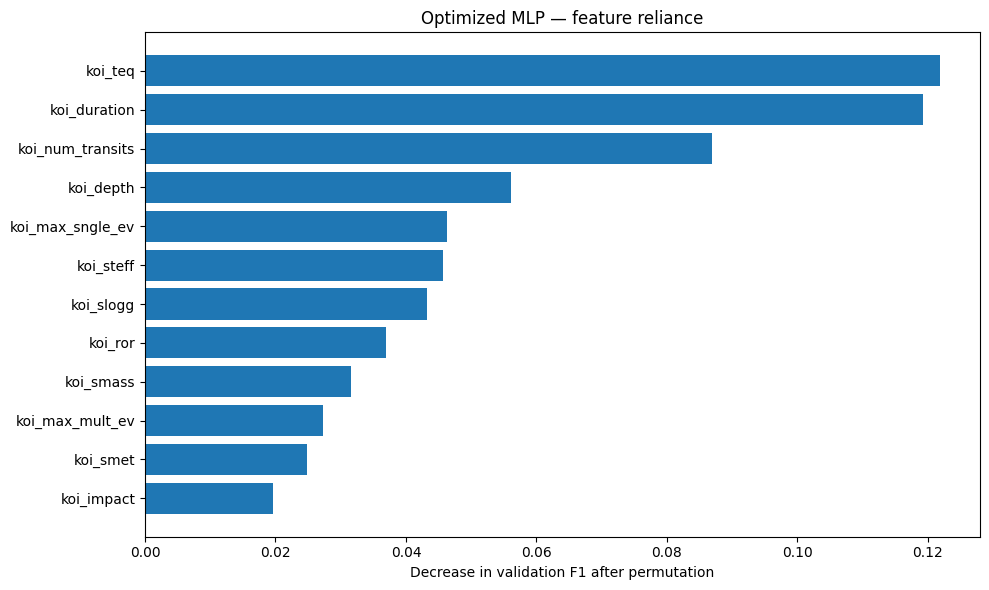

In [8]:
top = importance.head(12).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top['feature'], top['mean_f1_drop'])
plt.xlabel('Decrease in validation F1 after permutation')
plt.title('Optimized MLP — feature reliance')
plt.tight_layout()
plt.show()

## 2. Feature ablation: retrain after removing features

In [9]:
least_important = importance.tail(5)['feature'].tolist()
most_important = importance.head(3)['feature'].tolist()
subsets = {
    'All 19 features': list(X.columns),
    'Remove bottom 5': [f for f in X.columns if f not in least_important],
    'Remove top 3': [f for f in X.columns if f not in most_important]
}

ablation_rows = []
for experiment, features in subsets.items():
    for fold_number, (train_idx, val_idx) in enumerate(folds, 1):
        model = make_mlp().fit(X.iloc[train_idx][features], y[train_idx])
        score = f1_score(y[val_idx], model.predict(X.iloc[val_idx][features]))
        ablation_rows.append(dict(experiment=experiment, fold=fold_number,
                                  n_features=len(features), validation_f1=score,
                                  features_removed=';'.join(f for f in X.columns if f not in features)))

ablation_folds = pd.DataFrame(ablation_rows)
ablation_summary = (ablation_folds.groupby(['experiment', 'n_features', 'features_removed'])
                    ['validation_f1'].agg(['mean', 'std']).reset_index())
print(ablation_summary.round(5).to_string(index=False))
ablation_folds.to_csv('kepler_ablation_folds.csv', index=False)
ablation_summary.to_csv('kepler_ablation_summary.csv', index=False)

     experiment  n_features                            features_removed    mean     std
All 19 features          19                                             0.82805 0.00564
Remove bottom 5          14 koi_dor;koi_prad;koi_sma;koi_insol;koi_srad 0.82815 0.00615
   Remove top 3          16       koi_duration;koi_teq;koi_num_transits 0.80628 0.01016


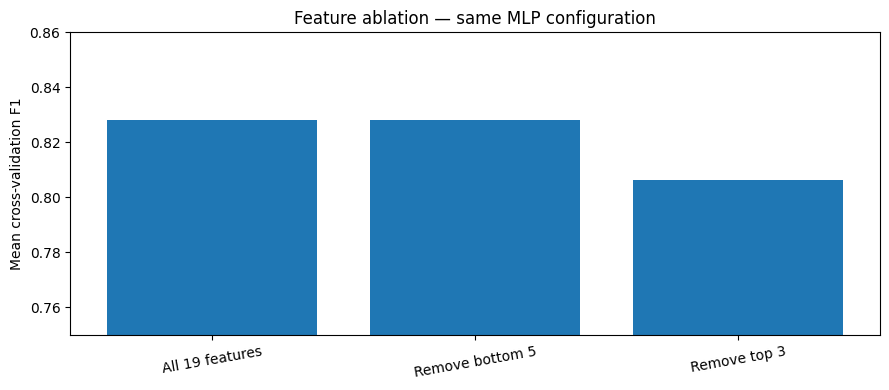

In [10]:
ordered = ['All 19 features', 'Remove bottom 5', 'Remove top 3']
summary_plot = ablation_summary.set_index('experiment').loc[ordered]
plt.figure(figsize=(9, 4))
plt.bar(summary_plot.index, summary_plot['mean'])
plt.ylabel('Mean cross-validation F1')
plt.ylim(0.75, 0.86)
plt.xticks(rotation=10)
plt.title('Feature ablation — same MLP configuration')
plt.tight_layout()
plt.show()